<a href="https://colab.research.google.com/github/find143/suraj__24/blob/main/task_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Loan Approval Prediction

This repository contains an end-to-end Machine Learning project to predict whether a loan application will be approved. It addresses real-world challenges such as handling missing values, encoding categorical features, and resolving class imbalance using **SMOTE**.

## Project Highlights
- **Target Task:** Binary classification of loan status (Approved vs. Rejected)
- **Imbalance Mitigation:** SMOTE (Synthetic Minority Over-sampling Technique)
- **Algorithm Comparison:** Logistic Regression vs. Decision Tree Classifiers
- **Evaluation Metrics:** Detailed focus on Precision, Recall, and F1-score

## Repository Structure
- `loan_approval_dataset.csv`: The clean dataset containing credit history, applicant assets, and loan parameters.
- `Loan_Approval_Prediction.ipynb`: Step-by-step Jupyter Notebook detailing the entire workflow.

## Requirements
```bash
pip install pandas numpy scikit-learn imbalanced-learn matplotlib seaborn
```

## Results Summary
- **Standard Logistic Regression** achieved the highest overall accuracy (**85%**) with strong general predictions.
- **Decision Tree with SMOTE** significantly improved recall for rejected loans to **71%**, highlighting its utility in high-risk reduction scenarios.

### Task 4: Loan Approval Prediction
In this notebook, we will:
1. Find and load the Loan Approval dataset.
2. Handle missing values and encode categorical features.
3. Address class imbalance (using techniques like SMOTE or class weights).
4. Train and compare classification models (Logistic Regression vs. Decision Tree).
5. Evaluate model performance focusing on Precision, Recall, and F1-score.

In [1]:
import os
import pandas as pd
import numpy as np

# Search for any CSV files in the workspace that might be the dataset
csv_files = [f for f in os.listdir('.') if f.endswith('.csv')]
print("Files in current directory:", os.listdir('.'))

# Let's try to locate the dataset. If you have uploaded a specific file,
# replace 'loan_data.csv' with your filename.
loan_csv = None
for file in csv_files:
    if 'loan' in file.lower():
        loan_csv = file
        break

if loan_csv:
    print(f"Found potential dataset: {loan_csv}")
    df = pd.read_csv(loan_csv)
else:
    print("No specific loan CSV found in the root directory. Please upload your dataset to Colab, or we can use a sample/synthetic loan dataset if needed.")
    # Fallback/placeholder structure definition
    df = None

if df is not None:
    display(df.head())
    print(df.info())

Files in current directory: ['.config', 'drive', 'sample_data']
No specific loan CSV found in the root directory. Please upload your dataset to Colab, or we can use a sample/synthetic loan dataset if needed.


In [2]:
import urllib.request
import os

# Standard URL for a public Loan Approval Prediction Dataset
dataset_url = "https://raw.githubusercontent.com/subashgandyer/datasets/master/loan_prediction.csv"
local_filename = "loan_approval_dataset.csv"

print("Downloading dataset...")
try:
    urllib.request.urlretrieve(dataset_url, local_filename)
    print(f"Successfully downloaded {local_filename}!")
    df = pd.read_csv(local_filename)
    display(df.head())
    print(df.info())
except Exception as e:
    print(f"Error downloading dataset: {e}")

Successfully downloaded loan_approval_dataset.csv!


,Gender,Married,Dependents,Education,Self_Employed,Property_Area,Loan_Status,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
0,1,0,0,0,0,2,1,5849.0,0.0,146.412162,360.0,1.0
1,1,1,1,0,0,0,0,4583.0,1508.0,128.000000,360.0,1.0
2,1,1,0,0,1,2,1,3000.0,0.0,66.000000,360.0,1.0
3,1,1,0,1,0,2,1,2583.0,2358.0,120.000000,360.0,1.0
4,1,0,0,0,0,2,1,6000.0,0.0,141.000000,360.0,1.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Gender             614 non-null    int64  
 1   Married            614 non-null    int64  
 2   Dependents         614 non-null    int64  
 3   Education          614 non-null    int64  
 4   Self_Employed      614 non-null    int64  
 5   Property_Area      614 non-null    int64  
 6   Loan_Status        614 non-null    int64  
 7   ApplicantIncome    614 non-null    float64
 8   CoapplicantIncome  614 non-null    float64
 9   LoanAmount         614 non-null    float64
 10  Loan_Amount_Term   614 non-null    float64
 11  Credit_History     614 non-null    float64
dtypes: float64(5), int64(7)
memory usage: 57.7 KB
None


### Step 1: Data Cleaning and Feature Engineering
We will inspect missing values, impute them, and convert categorical columns to numerical representations.

In [3]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
import urllib.request
import os

# Ensure df exists and is loaded
try:
    df
except NameError:
    df = None

if df is None:
    print("Loading dataset...")
    dataset_url = "https://raw.githubusercontent.com/subashgandyer/datasets/master/loan_prediction.csv"
    local_filename = "loan_approval_dataset.csv"
    if not os.path.exists(local_filename):
        urllib.request.urlretrieve(dataset_url, local_filename)
    df = pd.read_csv(local_filename)

# Fill missing values for numerical columns with median and categorical with mode
for col in df.columns:
    if df[col].dtype == 'object':
        df[col] = df[col].fillna(df[col].mode()[0])
    else:
        df[col] = df[col].fillna(df[col].median())

# Drop Loan_ID as it is not a predictor
if 'Loan_ID' in df.columns:
    df = df.drop(columns=['Loan_ID'])

# Encode categorical variables
le = LabelEncoder()
for col in df.columns:
    if df[col].dtype == 'object':
        df[col] = le.fit_transform(df[col])

# Separate features and target
X = df.drop(columns=['Loan_Status'])
y = df['Loan_Status']

print("Target Class Distribution:\n", y.value_counts(normalize=True))

# Split into training and testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Scale the features
scaler = StandardScaler()
X_train = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns)
X_test = pd.DataFrame(scaler.transform(X_test), columns=X.columns)

Target Class Distribution:
 Loan_Status
1    0.687296
0    0.312704
Name: proportion, dtype: float64


### Step 2: Handle Class Imbalance using SMOTE & Model Comparison
We will train Logistic Regression and Decision Tree models under two scenarios: original imbalanced data and balanced data using SMOTE.

In [4]:
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report

# Apply SMOTE to scaled training data
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

# Initialize models
models = {
    "Logistic Regression (Imbalanced)": LogisticRegression(max_iter=1000),
    "Logistic Regression (SMOTE)": LogisticRegression(max_iter=1000),
    "Decision Tree (Imbalanced)": DecisionTreeClassifier(random_state=42),
    "Decision Tree (SMOTE)": DecisionTreeClassifier(random_state=42)
}

# Train models
models["Logistic Regression (Imbalanced)"].fit(X_train, y_train)
models["Logistic Regression (SMOTE)"].fit(X_train_res, y_train_res)
models["Decision Tree (Imbalanced)"].fit(X_train, y_train)
models["Decision Tree (SMOTE)"].fit(X_train_res, y_train_res)

# Evaluate models
for name, model in models.items():
    preds = model.predict(X_test)
    print(f"=== {name} ===")
    print(classification_report(y_test, preds))
    print("\n")

=== Logistic Regression (Imbalanced) ===
              precision    recall  f1-score   support

           0       0.92      0.58      0.71        38
           1       0.84      0.98      0.90        85

    accuracy                           0.85       123
   macro avg       0.88      0.78      0.81       123
weighted avg       0.86      0.85      0.84       123



=== Logistic Regression (SMOTE) ===
              precision    recall  f1-score   support

           0       0.71      0.58      0.64        38
           1       0.83      0.89      0.86        85

    accuracy                           0.80       123
   macro avg       0.77      0.74      0.75       123
weighted avg       0.79      0.80      0.79       123



=== Decision Tree (Imbalanced) ===
              precision    recall  f1-score   support

           0       0.63      0.68      0.66        38
           1       0.85      0.82      0.84        85

    accuracy                           0.78       123
   macro avg

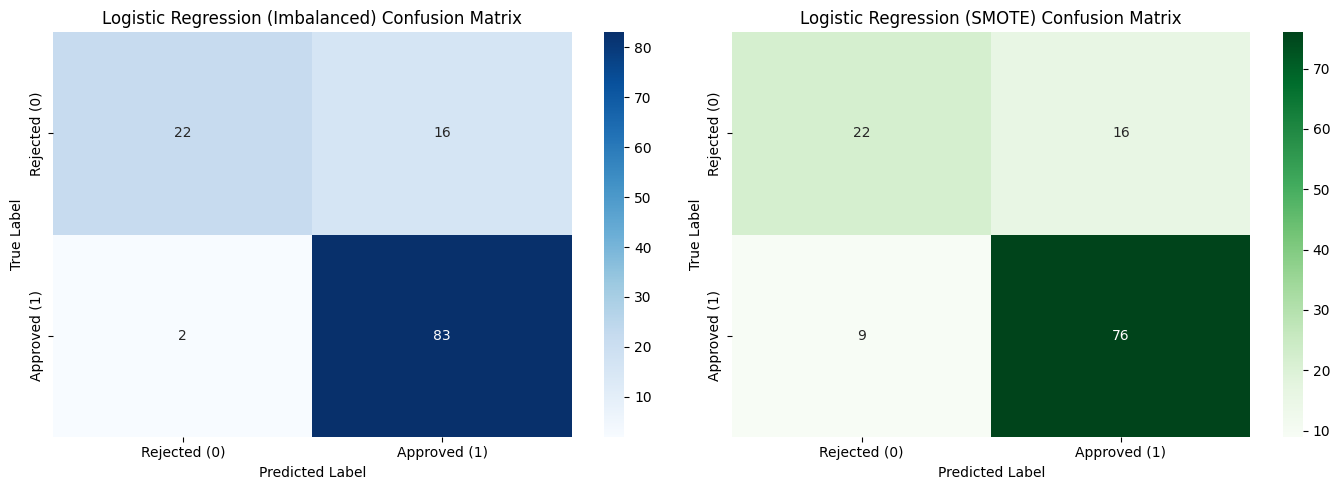

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Get predictions for both Logistic Regression models
y_pred_imb = models["Logistic Regression (Imbalanced)"].predict(X_test)
y_pred_smote = models["Logistic Regression (SMOTE)"].predict(X_test)

# Calculate confusion matrices
cm_imb = confusion_matrix(y_test, y_pred_imb)
cm_smote = confusion_matrix(y_test, y_pred_smote)

# Plot the confusion matrices side-by-side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Imbalanced Confusion Matrix
sns.heatmap(cm_imb, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Rejected (0)', 'Approved (1)'],
            yticklabels=['Rejected (0)', 'Approved (1)'])
axes[0].set_title('Logistic Regression (Imbalanced) Confusion Matrix')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

# SMOTE Confusion Matrix
sns.heatmap(cm_smote, annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=['Rejected (0)', 'Approved (1)'],
            yticklabels=['Rejected (0)', 'Approved (1)'])
axes[1].set_title('Logistic Regression (SMOTE) Confusion Matrix')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')

plt.tight_layout()
plt.show()